In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
IMG_SIZE = 128
BATCH_SIZE = 32

In [3]:
dataset = tf.keras.utils.image_dataset_from_directory(
    "Petimages",
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    shuffle=True
)

Found 24991 files belonging to 2 classes.


In [4]:
print(dataset.class_names)

['Cat', 'Dog']


In [5]:
dataset_size = tf.data.experimental.cardinality(dataset).numpy()

train_size = int(0.7 * dataset_size)
val_size = int(0.15 * dataset_size)

train_dataset = dataset.take(train_size)

remaining_dataset = dataset.skip(train_size)

validation_dataset = remaining_dataset.take(val_size)
test_dataset = remaining_dataset.skip(val_size)

In [6]:
print("Total batches:", dataset_size)
print("Training batches:", tf.data.experimental.cardinality(train_dataset).numpy())
print("Validation batches:", tf.data.experimental.cardinality(validation_dataset).numpy())
print("Testing batches:", tf.data.experimental.cardinality(test_dataset).numpy())

Total batches: 781
Training batches: 546
Validation batches: 117
Testing batches: 118


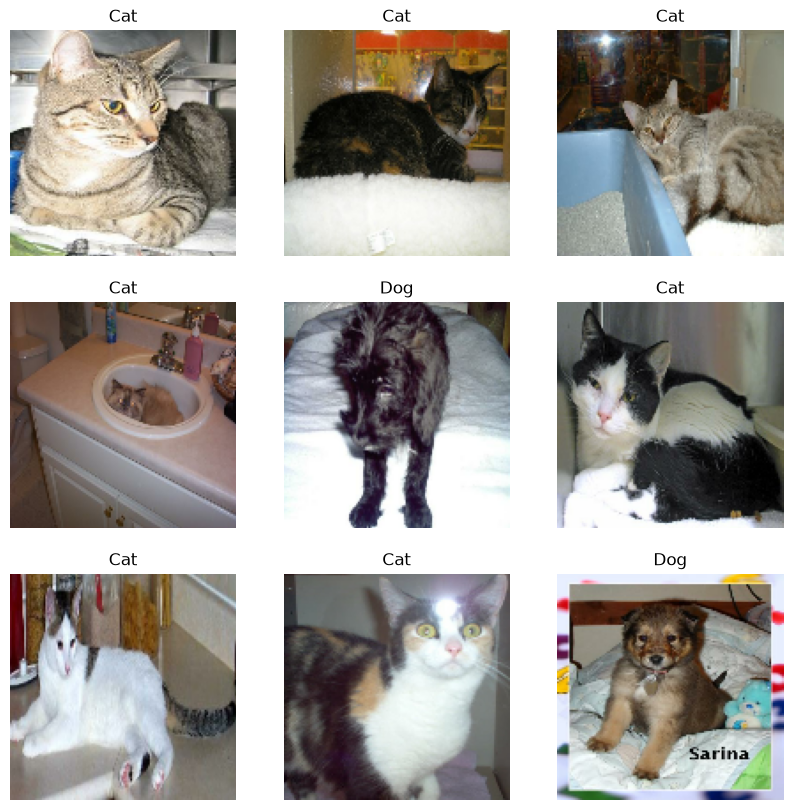

In [7]:
plt.figure(figsize=(10, 10))

class_names = dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.show()

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.cache().shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

validation_dataset = validation_dataset.cache().prefetch(
    buffer_size=AUTOTUNE
)

test_dataset = test_dataset.cache().prefetch(
    buffer_size=AUTOTUNE
)

In [9]:
model = tf.keras.Sequential([
    
    tf.keras.layers.Rescaling(
        1./255,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    ),

    # CNN Layer 1
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D(),

    # CNN Layer 2
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D(),

    # CNN Layer 3
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        activation='relu'
    ),
    tf.keras.layers.MaxPooling2D(),

    # Convert features into one vector
    tf.keras.layers.Flatten(),

    # Fully connected layer
    tf.keras.layers.Dense(
        128,
        activation='relu'
    ),

    # Prevent overfitting
    tf.keras.layers.Dropout(0.5),

    # Final prediction
    tf.keras.layers.Dense(
        1,
        activation='sigmoid'
    )
])

C:\Users\laggi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [12]:
import os
from PIL import Image

dataset_path = "dataset"

bad_images = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        file_path = os.path.join(root, file)

        try:
            img = Image.open(file_path)
            img.verify()
        except Exception:
            bad_images.append(file_path)

print("Bad images found:", len(bad_images))

for img in bad_images:
    print(img)

Bad images found: 0


In [13]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15
)

C:\Users\laggi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/15


546/546 ━━━━━━━━━━━━━━━━━━━━ 52s 89ms/step - accuracy: 0.6308 - loss: 0.6318 - val_accuracy: 0.7292 - val_loss: 0.5382
Epoch 2/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 46s 84ms/step - accuracy: 0.7517 - loss: 0.5111 - val_accuracy: 0.7778 - val_loss: 0.4770
Epoch 3/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 46s 84ms/step - accuracy: 0.7894 - loss: 0.4499 - val_accuracy: 0.8138 - val_loss: 0.4288
Epoch 4/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 44s 81ms/step - accuracy: 0.8211 - loss: 0.4010 - val_accuracy: 0.8146 - val_loss: 0.4033
Epoch 5/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 47s 86ms/step - accuracy: 0.8519 - loss: 0.3421 - val_accuracy: 0.8357 - val_loss: 0.3854
Epoch 6/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 53s 96ms/step - accuracy: 0.8793 - loss: 0.2842 - val_accuracy: 0.8379 - val_loss: 0.3928
Epoch 7/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 50s 91ms/step - accuracy: 0.9025 - loss: 0.2353 - val_accuracy: 0.8459 - val_loss: 0.3711
Epoch 8/15
546/546 ━━━━━━━━━━━━━━━━━━━━ 50s 91ms/step - accuracy: 0.9223 - loss: 0.1931 - val_accurac

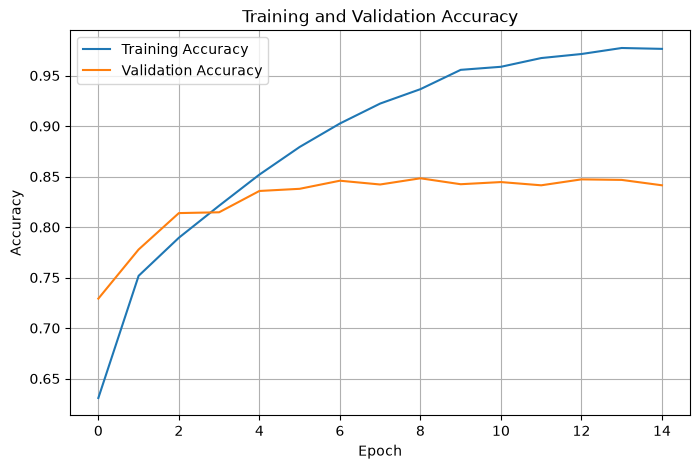

In [14]:
import matplotlib.pyplot as plt

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()

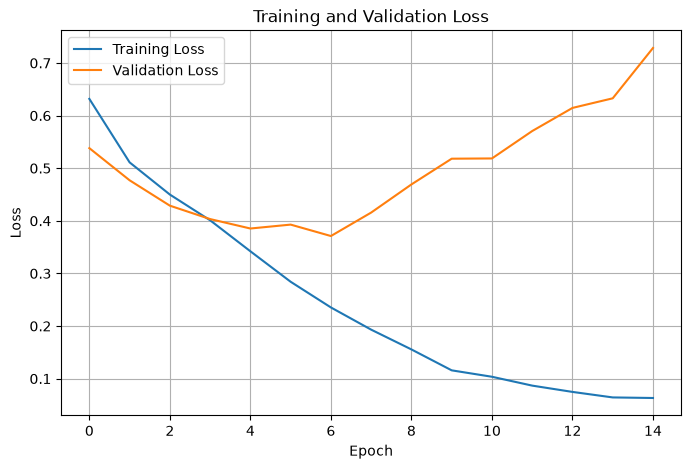

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.show()

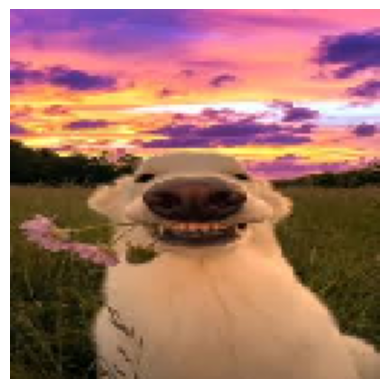

Prediction: DOG 🐶
Confidence: 99.65%


In [17]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

image_path = r"C:\kaam\images.jpg"

# Load image
img = load_img(image_path, target_size=(128, 128))

# Convert image to array
img_array = img_to_array(img)

# Add batch dimension
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array, verbose=0)[0][0]

# Display result
plt.imshow(img)
plt.axis("off")
plt.show()

if prediction >= 0.5:
    print("Prediction: DOG 🐶")
    print(f"Confidence: {prediction * 100:.2f}%")
else:
    print("Prediction: CAT 🐱")
    print(f"Confidence: {(1 - prediction) * 100:.2f}%")

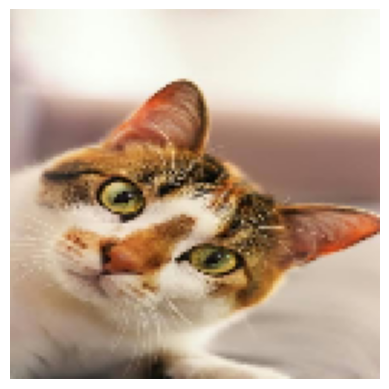

🐶 Prediction: DOG
Confidence: 99.97%


In [27]:
import tkinter as tk
from tkinter import filedialog
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.utils import load_img, img_to_array

# Open file selection window
root = tk.Tk()
root.withdraw()

image_path = filedialog.askopenfilename(
    title="Select a Cat or Dog Image",
    filetypes=[
        ("Image files", "*.jpg *.jpeg *.png *.bmp"),
        ("All files", "*.*")
    ]
)

if image_path:

    img = load_img(image_path, target_size=(128, 128))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(img_array, verbose=0)[0][0]

    plt.imshow(img)
    plt.axis("off")
    plt.show()

    if prediction >= 0.5:
        print("🐶 Prediction: DOG")
        print(f"Confidence: {prediction * 100:.2f}%")
    else:
        print("🐱 Prediction: CAT")
        print(f"Confidence: {(1 - prediction) * 100:.2f}%")

else:
    print("No image selected.")

In [30]:
import tensorflow as tf

base_dir = r"C:\kaam\cat and dog project\PetImages"

val_ds = tf.keras.utils.image_dataset_from_directory(
    base_dir,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=(128, 128),
    batch_size=32,
    label_mode="binary"
)

print("Validation dataset created!")
print("Classes:", val_ds.class_names)

Found 24992 files belonging to 2 classes.
Using 4998 files for validation.
Validation dataset created!
Classes: ['Cat', 'Dog']


In [31]:
loss, accuracy = model.evaluate(val_ds)

print("Final Validation Accuracy:", f"{accuracy * 100:.2f}%")
print("Final Validation Loss:", f"{loss:.4f}")

157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 28ms/step - accuracy: 0.9438 - loss: 0.2227
Final Validation Accuracy: 94.38%
Final Validation Loss: 0.2227


In [34]:
import numpy as np
from sklearn.metrics import confusion_matrix

y_true = []
y_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().flatten())
    y_pred.extend((predictions.flatten() >= 0.5).astype(int))

cm = confusion_matrix(y_true, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2281  161]
 [ 120 2436]]


In [ ]:
model.save("cat_dog_cnn.keras")

In [ ]:
# Start the API from the project folder with:
# python -m uvicorn backend.main:app --reload

import os
import requests
import tkinter as tk
from tkinter import filedialog

API_URL = "http://127.0.0.1:8000"

health_response = requests.get(f"{API_URL}/health", timeout=5)
health_response.raise_for_status()
print("Backend status:", health_response.json())

root = tk.Tk()
root.withdraw()
image_path = filedialog.askopenfilename(
    title="Select a Cat or Dog Image",
    filetypes=[("Image files", "*.jpg *.jpeg *.png *.bmp"), ("All files", "*.*")],
)
root.destroy()

if image_path:
    with open(image_path, "rb") as image_file:
        response = requests.post(
            f"{API_URL}/predict",
            files={"file": (os.path.basename(image_path), image_file)},
            timeout=60,
        )
    response.raise_for_status()
    result = response.json()
    print(f"Prediction: {result['prediction'].upper()}")
    print(f"Confidence: {result['confidence']:.2f}%")
else:
    print("No image selected; prediction skipped.")